# Ground control and check points: transformation accuracy on a real survey network

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/gcp_accuracy_en.ipynb)

**OpenSkyLab · notebook for the visual** [Ground control points and accuracy](https://openskylab.space/edu_viz_gcp_accuracy.html) · [česká verze](gcp_accuracy_cs.ipynb)

The visual simulates how the layout of ground control points and the georeferencing method affect the accuracy of a drone map. Here you test the same principles on real points of the ČÚZK survey network: every point has GNSS coordinates in ETRS89 as well as coordinates in S-JTSK and an elevation in Bpv. You estimate the conversion between the systems from a few ground control points and measure its accuracy on the other, independent check points. It is the same task as georeferencing an image block, only over tens of kilometres.

**Goal:** estimate a similarity (Helmert) transformation from ground control points, compare residuals on control and check points for different layouts, convert ellipsoidal heights to Bpv, judge how many check points are needed, and show when a more complex transformation does harm.

**Data:** ČÚZK trigonometric and densification points around Prague with S-JTSK coordinates, Bpv elevation and ETRS89 coordinates (B, L, ellipsoidal height) from static GNSS observations, BodovaPole service (layer 2).

**Tasks:** four. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 45 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and survey points

In [1]:
%pip install -q pyproj

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyproj import Transformer

CX, CY = -742000, -1045000    # ◀ parameter: centre of the area in S-JTSK (EPSG:5514, m), Prague
HALF = 30000                  # ◀ parameter: half the side of the area (m)
q = requests.get("https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer/2/query",
                 params={"geometry": f"{CX - HALF},{CY - HALF},{CX + HALF},{CY + HALF}", "geometryType": "esriGeometryEnvelope", "inSR": 5514,
                         "outFields": "CISLO_SMO5,CISLO,NAZEV_KU,Y,X,VYSKA,B,L,HEL", "returnGeometry": "false", "f": "json"}, timeout=120).json()
p = pd.DataFrame([f["attributes"] for f in q["features"]])
for k in ["Y", "X", "VYSKA", "B", "L", "HEL"]:
    p[k] = pd.to_numeric(p[k], errors="coerce")
p = p.dropna(subset=["Y", "X", "VYSKA", "B", "L", "HEL"]).reset_index(drop=True)
# "map": GNSS positions in ETRS89 converted to UTM 33N; "truth": S-JTSK (EPSG:5514 axes: x = −Y, y = −X)
p["E"], p["N"] = Transformer.from_crs(4258, 32633, always_xy=True).transform(p.L.values, p.B.values)
p["sx"], p["sy"] = -p.Y, -p.X
SRC, DST = p[["E", "N"]].values, p[["sx", "sy"]].values
C0 = SRC.mean(axis=0)
print(f"points: {len(p)} in an area of {2 * HALF / 1000:.0f} × {2 * HALF / 1000:.0f} km")
p[["CISLO_SMO5", "CISLO", "NAZEV_KU", "Y", "X", "VYSKA", "B", "L", "HEL"]].head()

points: 148 in an area of 60 × 60 km


,CISLO_SMO5,CISLO,NAZEV_KU,Y,X,VYSKA,B,L,HEL
0,40877,16,Mělnické Vtelno,718092.47,1015448.60,287.54,50.362908,14.712595,331.726
1,40857,17,Bezno,712975.05,1015954.46,281.26,50.364472,14.784829,325.371
2,40718,19,Jelenice u Mělníka,729834.40,1016756.71,213.72,50.337158,14.551541,258.041
3,40888,21,Vysoká Libeň,721775.12,1016558.23,301.40,50.348624,14.663372,345.634
4,40709,28,Liblice,726282.60,1019069.71,224.19,50.320837,14.605334,268.497


## 2. Helmert transformation from ground control points

A similarity transformation has 4 parameters (shift x, y, rotation, scale): x' = a·x − b·y + tₓ, y' = b·x + a·y + t_y. We estimate it by least squares from the ground control points and then apply it to all points. A residual on a control point only says how well the transformation adapted to those points. Accuracy is shown by check points that did not enter the computation. RMSE_H = √(mean(Δx² + Δy²)).

Note: S-JTSK has its own distortions and the scale of the Křovák projection changes with latitude, so even the best similarity transformation over such an area is not perfect. ČÚZK therefore converts with a transformation plus a correction grid. For us this is an advantage: there is a real error, unknown in advance, that the check points have to reveal.

cluster in a corner: 5 control points, 143 check points
RMSE_H on control points 0.028 m, on check points 1.117 m, largest check point residual 2.97 m


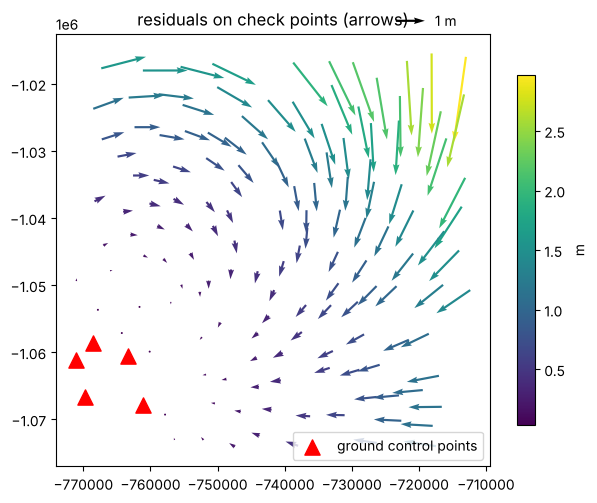

In [3]:
def fit(src, dst, kind="helmert"):
    """Least-squares transformation parameters src → dst (coordinates relative to the centre C0)."""
    x, y = (src - C0).T
    if kind == "helmert":
        A = np.zeros((2 * len(x), 4)); A[0::2] = np.c_[x, -y, np.ones_like(x), 0 * x]; A[1::2] = np.c_[y, x, 0 * x, np.ones_like(x)]
        return kind, np.linalg.lstsq(A, dst.ravel(), rcond=None)[0]
    cols = {"affine": [1, x, y], "polynomial 2": [1, x, y, x * x, x * y, y * y]}[kind]
    B = np.c_[tuple(np.broadcast_to(c, x.shape) for c in cols)]
    return kind, np.linalg.lstsq(B, dst, rcond=None)[0]

def apply(model, src):
    kind, par = model; x, y = (src - C0).T
    if kind == "helmert":
        a, b, tx, ty = par; return np.c_[a * x - b * y + tx, b * x + a * y + ty]
    cols = [1, x, y] if kind == "affine" else [1, x, y, x * x, x * y, y * y]
    return np.c_[tuple(np.broadcast_to(c, x.shape) for c in cols)] @ par

def pick(targets):
    """For each target (fraction of the area's width and height) find the nearest real point."""
    x0, y0 = SRC.min(axis=0); x1, y1 = SRC.max(axis=0)
    idx = [int(np.argmin(np.hypot(SRC[:, 0] - (x0 + fx * (x1 - x0)), SRC[:, 1] - (y0 + fy * (y1 - y0))))) for fx, fy in targets]
    return np.array(list(dict.fromkeys(idx)))

LAYOUTS = {
    "corners + centre":    pick([(0, 0), (0, 1), (1, 0), (1, 1), (0.5, 0.5)]),
    "1 in the centre":     pick([(0.5, 0.5)]),
    "cluster in a corner": np.argsort(np.hypot(*(SRC - SRC.min(axis=0)).T))[:5],
    "along a line only":   pick([(f, 0.5) for f in np.linspace(0, 1, 5)]),
    "10 evenly":           pick([(fx, fy) for fx in (0.1, 0.5, 0.9) for fy in (0.1, 0.5, 0.9)] + [(0.3, 0.3)]),
}
LAYOUT = "cluster in a corner"   # ◀ parameter: one of the layouts above
gcp = LAYOUTS[LAYOUT]; chk = np.setdiff1d(np.arange(len(p)), gcp)
model = fit(SRC[gcp], DST[gcp], "helmert") if len(gcp) >= 2 else None
pred = apply(model, SRC) if model else SRC - SRC[gcp].mean(axis=0) + DST[gcp].mean(axis=0)   # one point: shift only
res = pred - DST
rmse = lambda r: np.sqrt((r ** 2).sum(axis=1).mean())
print(f"{LAYOUT}: {len(gcp)} control points, {len(chk)} check points")
print(f"RMSE_H on control points {rmse(res[gcp]):.3f} m, on check points {rmse(res[chk]):.3f} m, largest check point residual {np.hypot(*res[chk].T).max():.2f} m")
fig, ax = plt.subplots(figsize=(7, 6.5))
q_ = ax.quiver(p.sx[chk], p.sy[chk], res[chk, 0], res[chk, 1], np.hypot(*res[chk].T), cmap="viridis", scale=15, scale_units="width")
ax.scatter(p.sx[gcp], p.sy[gcp], marker="^", s=120, c="r", label="ground control points"); ax.quiverkey(q_, 0.85, 1.03, 1, "1 m", labelpos="E")
ax.set_aspect("equal"); ax.legend(loc="lower right"); ax.set_title("residuals on check points (arrows)"); plt.colorbar(q_, label="m", shrink=0.7); plt.show()

> **✏️ Task 1.** For the “cluster in a corner” compare RMSE_H on the control points and on the check points. Why are the residuals on the control points so small, and why can they not be reported as accuracy? Where on the map do the check point residuals grow? Then choose “corners + centre”: why is the residual on the control points now larger than on the check points?

*Your answer:* 

## 3. Comparing layouts, position and height

GNSS gives the ellipsoidal height h, maps in Czechia use the normal height in Bpv: H = h − ζ, where ζ is the height anomaly (about 44–46 m around Prague). If we estimate ζ from the control points as a constant or as a plane, we get heights at the check points. RMSE_V = √(mean ΔH²).

A single control point can only give a shift in position. UTM and S-JTSK, however, are rotated relative to each other and have a different scale, so the error here comes out in kilometres. For an image block from RTK or PPK, rotation and scale are already set by the image positions.

                     control  RMSE_H control (m)  RMSE_H check (m)  \
corners + centre         5.0               0.778             0.387   
1 in the centre          1.0               0.000          3062.219   
cluster in a corner      5.0               0.028             1.117   
along a line only        5.0               0.172             0.492   
10 evenly               10.0               0.528             0.398   

                     RMSE_V ζ constant (m)  RMSE_V ζ plane (m)  
corners + centre                     0.424               0.073  
1 in the centre                      0.433                 NaN  
cluster in a corner                  0.903               0.164  
along a line only                    0.433               0.352  
10 evenly                            0.424               0.055  

ζ over the area: 44.11 to 45.88 m. Whoever forgets to subtract ζ has heights off by 45.0 m.


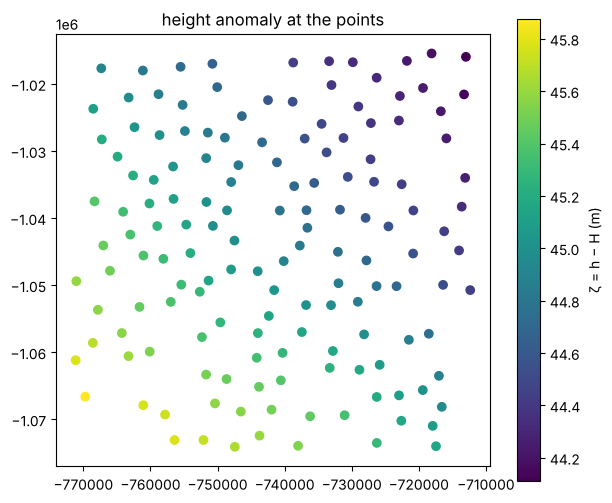

In [4]:
zeta = (p.HEL - p.VYSKA).values
x, y = (SRC - C0).T
rows = {}
for name, g in LAYOUTS.items():
    c = np.setdiff1d(np.arange(len(p)), g)
    r = (apply(fit(SRC[g], DST[g]), SRC) if len(g) >= 2 else SRC - SRC[g].mean(axis=0) + DST[g].mean(axis=0)) - DST
    const = zeta[g].mean()
    plane = np.linalg.lstsq(np.c_[np.ones(len(g)), x[g], y[g]], zeta[g], rcond=None)[0] if len(g) >= 3 else None
    rows[name] = {"control": len(g), "RMSE_H control (m)": rmse(r[g]), "RMSE_H check (m)": rmse(r[c]),
                  "RMSE_V ζ constant (m)": np.sqrt(((const - zeta[c]) ** 2).mean()),
                  "RMSE_V ζ plane (m)": np.sqrt(((np.c_[np.ones(len(c)), x[c], y[c]] @ plane - zeta[c]) ** 2).mean()) if plane is not None else np.nan}
print(pd.DataFrame(rows).T.round(3))
print(f"\nζ over the area: {zeta.min():.2f} to {zeta.max():.2f} m. Whoever forgets to subtract ζ has heights off by {zeta.mean():.1f} m.")
fig, ax = plt.subplots(figsize=(7, 6)); sc = ax.scatter(p.sx, p.sy, c=zeta, cmap="viridis"); plt.colorbar(sc, label="ζ = h − H (m)"); ax.set_aspect("equal"); ax.set_title("height anomaly at the points"); plt.show()

> **✏️ Task 2.** Which layout is best for position and which for height? Why do points “along a line only” still hold the position but fail to determine the plane of heights (the tilt)? What does a single point in the centre do, and what is it still good for when you have RTK or PPK? Why would mixing up ellipsoidal and normal height be an error of tens of metres in Czechia?

*Your answer:* 

## 4. How many check points?

We estimate accuracy from a limited number of check points, so the RMSE itself is uncertain. We draw 12 or 30 check points at random many times and look at how much the estimate varies.

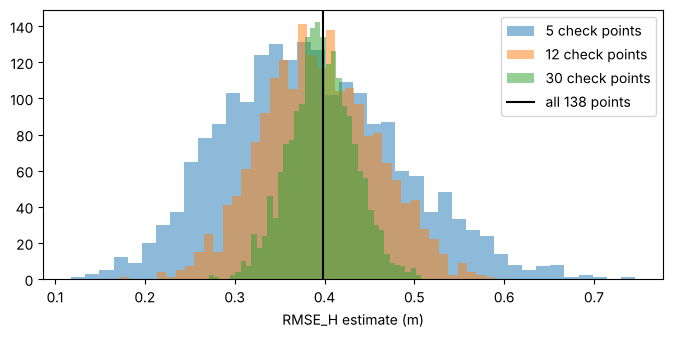

                 5 points  12 points  30 points
5th percentile      0.237      0.294      0.337
median              0.378      0.392      0.396
95th percentile     0.556      0.501      0.456


In [5]:
LAYOUT_N = "10 evenly"        # ◀ parameter: layout of the control points
COUNTS = [5, 12, 30]          # ◀ parameter: numbers of check points
DRAWS = 2000                  # ◀ parameter: number of random draws
g = LAYOUTS[LAYOUT_N]; c = np.setdiff1d(np.arange(len(p)), g)
r = np.hypot(*(apply(fit(SRC[g], DST[g]), SRC) - DST).T)[c]
rng = np.random.default_rng(1)
est = {n: np.array([np.sqrt((rng.choice(r, n, replace=False) ** 2).mean()) for _ in range(DRAWS)]) for n in COUNTS if n <= len(r)}
plt.figure(figsize=(8, 3.5))
for n, e in est.items():
    plt.hist(e, 40, alpha=0.5, label=f"{n} check points")
plt.axvline(np.sqrt((r ** 2).mean()), color="k", label=f"all {len(r)} points"); plt.xlabel("RMSE_H estimate (m)"); plt.legend(); plt.show()
print(pd.DataFrame({f"{n} points": {"5th percentile": np.percentile(e, 5), "median": np.median(e), "95th percentile": np.percentile(e, 95)} for n, e in est.items()}).round(3))

> **✏️ Task 3.** How wide is the range of the RMSE_H estimate (5th to 95th percentile) with 5, 12 and 30 check points? Why does ASPRS require at least 30 check points? Why must the check points be spread over the whole area and not, say, only along a road?

*Your answer:* 

## 5. More complex transformations and few points

The Helmert transformation has 4 parameters, the affine one 6 (two different scales and a shear on top) and a 2nd-degree polynomial 12. More parameters adapt better to the control points. Whether that also helps on the check points depends on whether the real difference between the systems has such a shape, and on how many control points there are. We draw the control points at random and look at the median and at the 90th percentile (an unlucky draw).

RMSE_H on check points (m), median:
                helmert  affine  polynomial 2
control points                               
3                 0.572   0.773           NaN
4                 0.538   0.653           NaN
6                 0.488   0.563         0.371
8                 0.461   0.531         0.202
12                0.446   0.484         0.147
20                0.426   0.447         0.124
40                0.417   0.429         0.105
90th percentile:
                helmert  affine  polynomial 2
control points                               
3                 0.800   2.183           NaN
4                 0.717   0.971           NaN
6                 0.605   0.745         1.775
8                 0.554   0.676         0.373
12                0.501   0.588         0.218
20                0.461   0.512         0.160
40                0.442   0.458         0.120


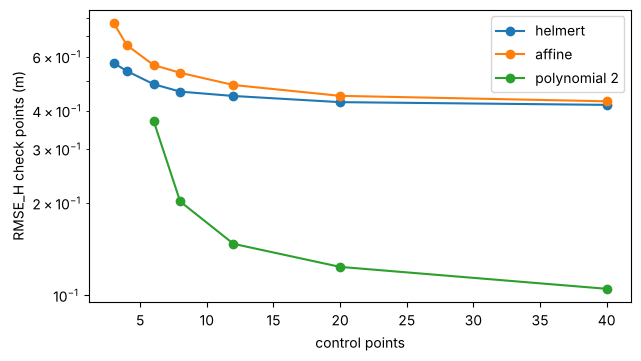

In [6]:
KINDS = ["helmert", "affine", "polynomial 2"]
N_GCP = [3, 4, 6, 8, 12, 20, 40]   # ◀ parameter: numbers of control points
REPEAT = 200                  # ◀ parameter: number of draws for each number
need = {"helmert": 2, "affine": 3, "polynomial 2": 6}
out = {k: [] for k in KINDS}
for n in N_GCP:
    for k in KINDS:
        vals = []
        for _ in range(REPEAT):
            g = rng.choice(len(p), n, replace=False); c = np.setdiff1d(np.arange(len(p)), g)
            if n < need[k]: break
            vals.append(rmse(apply(fit(SRC[g], DST[g], k), SRC[c]) - DST[c]))
        out[k].append((np.median(vals), np.percentile(vals, 90)) if vals else (np.nan, np.nan))
tab = pd.DataFrame({k: [v[0] for v in out[k]] for k in KINDS}, index=pd.Index(N_GCP, name="control points"))
p90 = pd.DataFrame({k: [v[1] for v in out[k]] for k in KINDS}, index=tab.index)
print("RMSE_H on check points (m), median:"); print(tab.round(3)); print("90th percentile:"); print(p90.round(3))
tab.plot(marker="o", logy=True, figsize=(7, 3.8), ylabel="RMSE_H check points (m)"); plt.show()

> **✏️ Task 4.** Which transformation is best with 3–4 points and which with 40 points? Why is the affine transformation slightly worse than the Helmert one at every count, whereas the 2nd-degree polynomial is clearly better from 8 points on? What does that say about the shape of the real difference between S-JTSK and UTM? Compare the 90th percentile of the polynomial with 6 points with its median: how risky is a model with almost as many parameters as observations? How would you choose the transformation model, or the number of camera self-calibration parameters, in practice?

*Your answer:* 

---
### Data sources and references

- Survey control: © ČÚZK, service https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer (CC BY 4.0); point descriptions at https://geoportal.cuzk.gov.cz
- ASPRS (2023). *ASPRS Positional Accuracy Standards for Digital Geospatial Data*, Edition 2, Version 1.0 (RMSE_H, RMSE_V, at least 30 check points).
- Sanz-Ablanedo, E., Chandler, J. H., Rodríguez-Pérez, J. R., Ordóñez, C. (2018). Accuracy of Unmanned Aerial Vehicle (UAV) and SfM Photogrammetry Survey as a Function of the Number and Location of Ground Control Points Used. *Remote Sensing* 10(10), 1606.
- Hofmann-Wellenhof, B., Lichtenegger, H., Wasle, E. (2008). *GNSS – Global Navigation Satellite Systems*. Springer (ellipsoidal and normal height, height anomaly).

### How to cite

OpenSkyLab (2026). Ground control and check points: transformation accuracy on a real survey network [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/gcp_accuracy_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*